# Data Preprocessing for Clustering (Customer Segmentation)
Clustering is **unsupervised**: there is no target (`y`), so there is no train-test split and no leakage columns to drop.
The main job here is to turn the raw *transaction-level* data (one row per product line) into a *customer-level* table (one row per customer),
then transform and scale those features so distance-based algorithms like K-Means work properly.

In [1]:
#Import required libraries and load the dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

sns.set_style("whitegrid")

#Load Dataset (dates in this file are day-first, e.g. 01-12-2010)
df = pd.read_csv("../data/online_retail.csv")
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], dayfirst=True)

print("Shape:", df.shape)
df.head()

Shape: (541910, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [2]:
#Basic Data Audit
print("Rows, Columns:", df.shape)
print("\nData types:\n", df.dtypes)
print("\nMissing values:\n", df.isnull().sum()[df.isnull().sum() > 0])
print("\nDuplicate rows:", df.duplicated().sum())
print("\nDate range:", df["InvoiceDate"].min(), "to", df["InvoiceDate"].max())
print("\nNumeric statistics:\n", df[["Quantity", "Price"]].describe())

Rows, Columns: (541910, 8)

Data types:
 Invoice                   str
StockCode                 str
Description               str
Quantity                int64
InvoiceDate    datetime64[us]
Price                 float64
Customer ID           float64
Country                   str
dtype: object

Missing values:
 Description      1454
Customer ID    135080
dtype: int64

Duplicate rows: 5268

Date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00

Numeric statistics:
             Quantity          Price
count  541910.000000  541910.000000
mean        9.552234       4.611138
std       218.080957      96.759765
min    -80995.000000  -11062.060000
25%         1.000000       1.250000
50%         3.000000       2.080000
75%        10.000000       4.130000
max     80995.000000   38970.000000


In [3]:
#Missing Value table
missing_table = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": df.isnull().mean() * 100
})
missing_table = missing_table[missing_table["Missing Count"] > 0].sort_values("Missing Count", ascending=False)
missing_table

,Missing Count,Missing Percentage
Customer ID,135080,24.926648
Description,1454,0.268310


In [4]:
#Remove Duplicate Records
print("Shape before removing duplicates:", df.shape)
df = df.drop_duplicates()
print("Shape after removing duplicates:", df.shape)

Shape before removing duplicates: (541910, 8)
Shape after removing duplicates: (536642, 8)


In [5]:
#Handle Missing Values
# Customer ID: we cannot build customer segments without knowing the customer -> drop these rows
# (imputing an ID would invent fake customers, unlike 'agent' in the hotel data where missing meant 'no agent')
# Description: not used for clustering, so missing descriptions do not matter
print("Rows before:", df.shape[0])
df = df.dropna(subset=["Customer ID"])
df["Customer ID"] = df["Customer ID"].astype(int)
print("Rows after dropping missing Customer ID:", df.shape[0])
print("Missing in key columns:", df[["Customer ID", "Quantity", "Price", "InvoiceDate"]].isnull().sum().sum())

Rows before: 536642
Rows after dropping missing Customer ID: 401605
Missing in key columns: 0


In [6]:
#Check Invalid / Suspicious Values
is_cancel = df["Invoice"].astype(str).str.startswith("C")
print("Cancelled invoices (start with 'C'):", is_cancel.sum())
print("Quantity <= 0:", (df["Quantity"] <= 0).sum())
print("Price <= 0:", (df["Price"] <= 0).sum())

# Non-product codes (postage, manual adjustments, bank charges, fees, vouchers...) are not real purchases
non_product = ~df["StockCode"].astype(str).str.match(r"^\d{5}")
print("Non-product stock codes:", non_product.sum())
print(df.loc[non_product, "StockCode"].value_counts().head(10))

Cancelled invoices (start with 'C'): 8872
Quantity <= 0: 8872
Price <= 0: 40
Non-product stock codes: 1916
StockCode
POST            1197
M                460
C2               134
D                 77
DOT               16
CRUK              16
BANK CHARGES      12
PADS               4
Name: count, dtype: int64


In [7]:
#Keep cancellation info as a feature BEFORE removing cancelled rows
# A customer who cancels often behaves differently from one who never does
df["IsCancel"] = df["Invoice"].astype(str).str.startswith("C")
cancel_info = df.groupby("Customer ID").agg(
    cancel_invoices=("Invoice", lambda s: s[df.loc[s.index, "IsCancel"]].nunique()),
    total_invoices=("Invoice", "nunique")
)
cancel_info["CancelRate"] = cancel_info["cancel_invoices"] / cancel_info["total_invoices"]
cancel_info = cancel_info[["CancelRate"]]

In [8]:
#Apply the cleaning removals
before = df.shape[0]
df = df[~df["IsCancel"]]                                      # cancelled orders
df = df[(df["Quantity"] > 0) & (df["Price"] > 0)]             # impossible / free / adjustment rows
df = df[df["StockCode"].astype(str).str.match(r"^\d{5}")]     # real products only
df = df.drop(columns="IsCancel")
print(f"Rows removed: {before - df.shape[0]}")
print("Shape after cleaning:", df.shape)

Rows removed: 10455
Shape after cleaning: (391150, 8)


In [9]:
#Feature Engineering (transaction level)
# Money spent on each line
df["TotalPrice"] = df["Quantity"] * df["Price"]

# Reference date for Recency = one day after the last purchase in the data
snapshot_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)
print("Snapshot date:", snapshot_date)
df[["Customer ID", "Quantity", "Price", "TotalPrice"]].head()

Snapshot date: 2011-12-10 12:50:00


,Customer ID,Quantity,Price,TotalPrice
0,17850,6,2.55,15.30
1,17850,6,3.39,20.34
2,17850,8,2.75,22.00
3,17850,6,3.39,20.34
4,17850,6,3.39,20.34


In [10]:
#Build the customer-level table (one row per customer) - RFM + extra behaviour features
customer_df = df.groupby("Customer ID").agg(
    Recency=("InvoiceDate", lambda x: (snapshot_date - x.max()).days),   # days since last purchase
    Frequency=("Invoice", "nunique"),                                    # number of orders
    Monetary=("TotalPrice", "sum"),                                      # total money spent
    TotalItems=("Quantity", "sum"),                                      # total units bought
    UniqueProducts=("StockCode", "nunique"),                             # product variety
    AvgUnitPrice=("Price", "mean")                                       # typical price level of items bought
)

# Average money per order
customer_df["AvgOrderValue"] = customer_df["Monetary"] / customer_df["Frequency"]

# Add cancellation rate (customers with no remaining valid orders were already removed)
customer_df = customer_df.join(cancel_info, how="left")
customer_df["CancelRate"] = customer_df["CancelRate"].fillna(0)

print("Customer table shape:", customer_df.shape)
customer_df.head()

Customer table shape: (4334, 8)


,Recency,Frequency,Monetary,TotalItems,UniqueProducts,AvgUnitPrice,AvgOrderValue,CancelRate
Customer ID,,,,,,,,
12346,326,1,77183.60,74215,1,1.040000,77183.600000,0.5
12347,2,7,4310.00,2458,103,2.644011,615.714286,0.0
12348,75,4,1437.24,2332,21,0.692963,359.310000,0.0
12349,19,1,1457.55,630,72,4.237500,1457.550000,0.0
12350,310,1,294.40,196,16,1.581250,294.400000,0.0


In [11]:
#Check the customer table
print("Missing values:", customer_df.isnull().sum().sum())
print("Duplicate customers:", customer_df.index.duplicated().sum())
customer_df.describe().T

Missing values: 0
Duplicate customers: 0


,count,mean,std,min,25%,50%,75%,max
Recency,4334.0,92.703046,100.177047,1.0000,18.000000,51.000000,143.000000,374.00
Frequency,4334.0,4.245962,7.634989,1.0000,1.000000,2.000000,5.000000,206.00
Monetary,4334.0,2015.973152,8903.673825,3.7500,304.240000,662.565000,1631.622500,279138.02
TotalItems,4334.0,1186.383018,5040.619437,1.0000,159.250000,377.500000,989.750000,196844.00
UniqueProducts,4334.0,61.426165,85.307437,1.0000,16.000000,35.000000,77.000000,1785.00
AvgUnitPrice,4334.0,3.451771,8.860856,0.1225,2.154759,2.827541,3.689205,434.65
AvgOrderValue,4334.0,415.482864,1800.895810,3.7500,177.197500,289.561250,423.409375,84236.25
CancelRate,4334.0,0.105670,0.165927,0.0000,0.000000,0.000000,0.200000,0.80


Skewness per feature:
 AvgOrderValue     41.455369
AvgUnitPrice      36.612794
TotalItems        20.414263
Monetary          19.578006
Frequency         11.949415
UniqueProducts     6.917591
CancelRate         1.404736
Recency            1.242934
dtype: float64


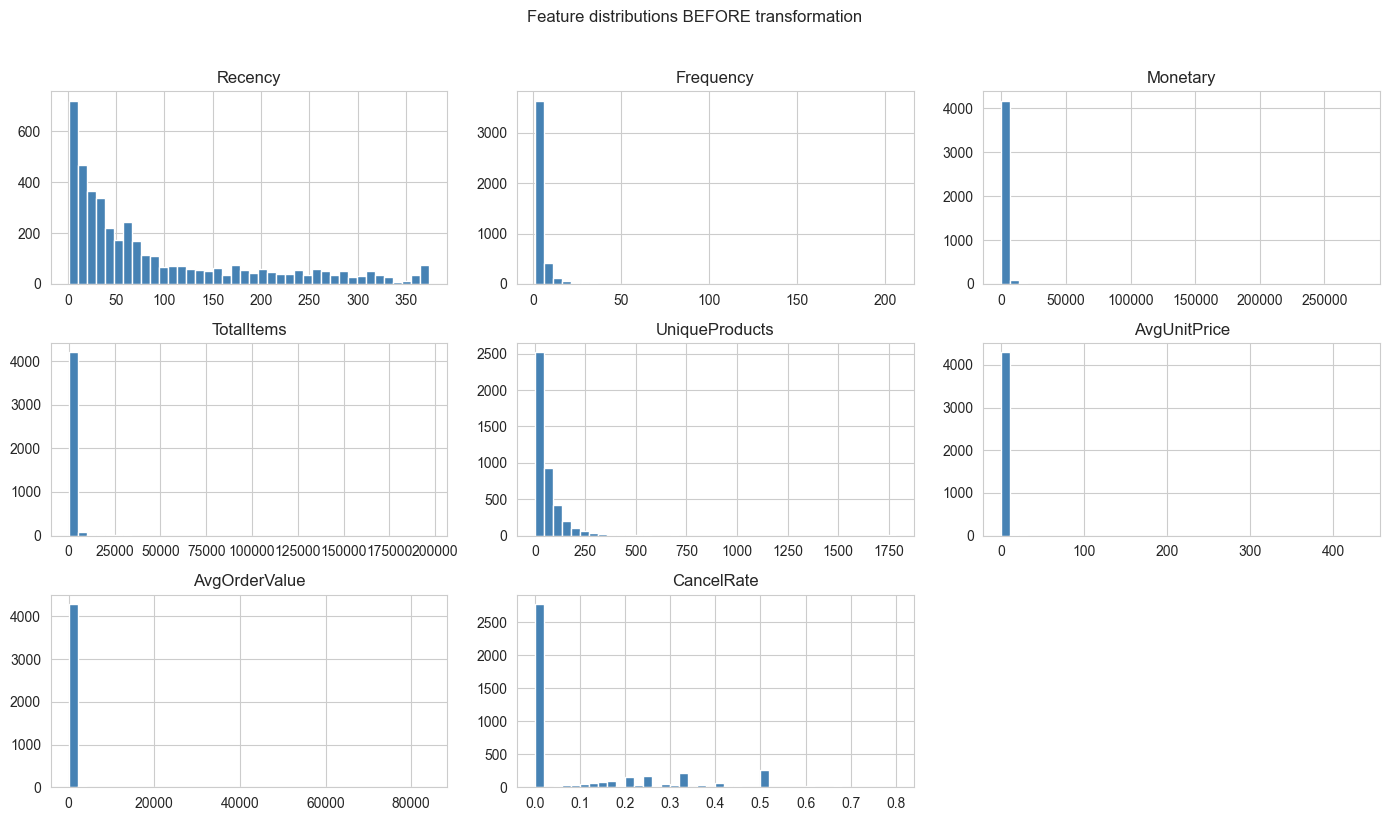

In [12]:
#Check skewness (clustering is sensitive to skewed, long-tailed features)
skew = customer_df.skew().sort_values(ascending=False)
print("Skewness per feature:\n", skew)

customer_df.hist(bins=40, figsize=(14, 8), color="steelblue")
plt.suptitle("Feature distributions BEFORE transformation", y=1.02)
plt.tight_layout()
plt.show()

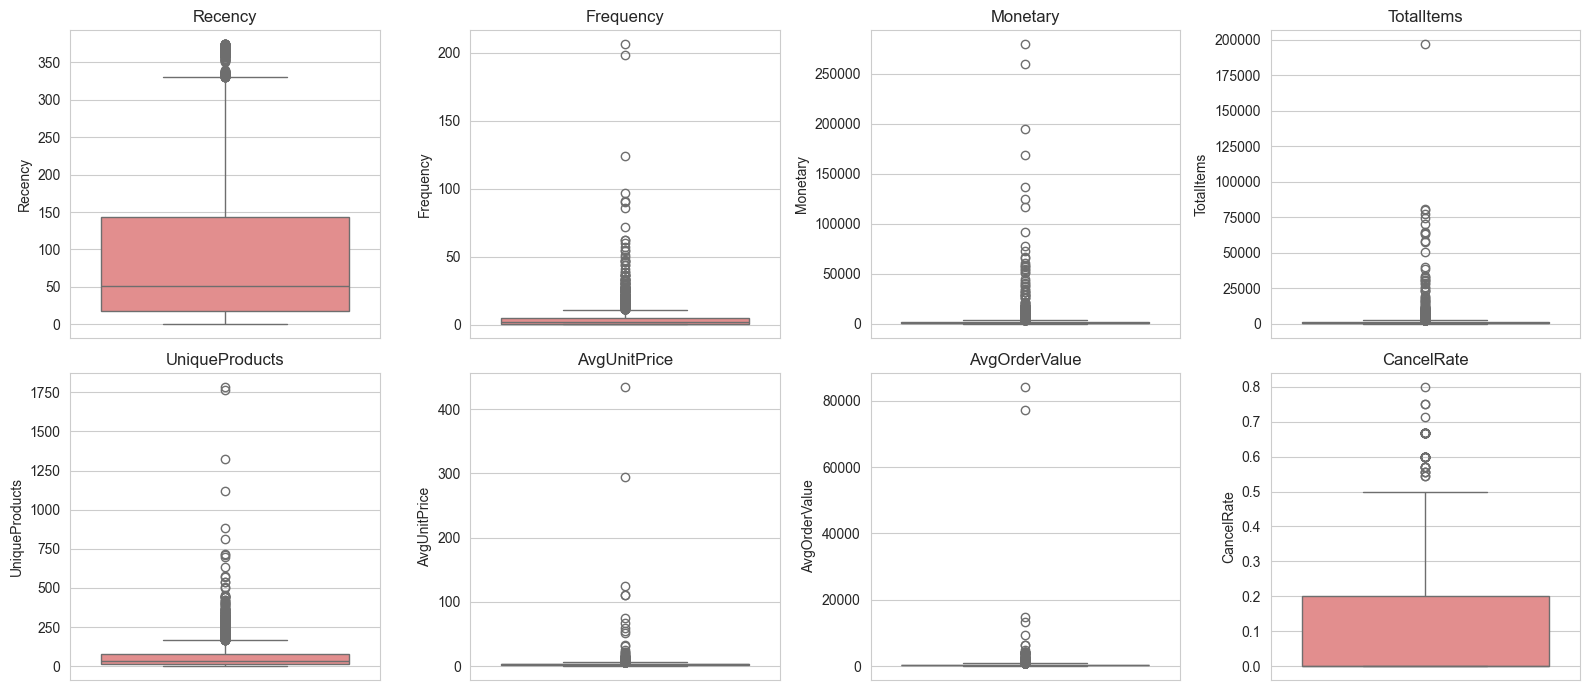

In [13]:
#Outlier check (boxplots)
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.flatten(), customer_df.columns):
    sns.boxplot(y=customer_df[col], ax=ax, color="lightcoral")
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [14]:
#Treat extreme outliers
# K-Means is distance based, so a handful of huge buyers can hijack a whole cluster.
# We cap (winsorize) at the 1st and 99th percentile instead of deleting customers, so nobody is lost.
cap_cols = ["Frequency", "Monetary", "TotalItems", "UniqueProducts", "AvgUnitPrice", "AvgOrderValue"]
customer_capped = customer_df.copy()
for col in cap_cols:
    low, high = customer_capped[col].quantile([0.01, 0.99])
    customer_capped[col] = customer_capped[col].clip(lower=low, upper=high)

print("Max Monetary before capping:", round(customer_df["Monetary"].max(), 2))
print("Max Monetary after capping: ", round(customer_capped["Monetary"].max(), 2))

Max Monetary before capping: 279138.02
Max Monetary after capping:  18715.31


Skewness after log transform:
 CancelRate        1.404736
Frequency         1.010630
AvgUnitPrice      0.414093
Monetary          0.287666
AvgOrderValue     0.116182
TotalItems        0.031936
UniqueProducts   -0.299011
Recency          -0.378920
dtype: float64


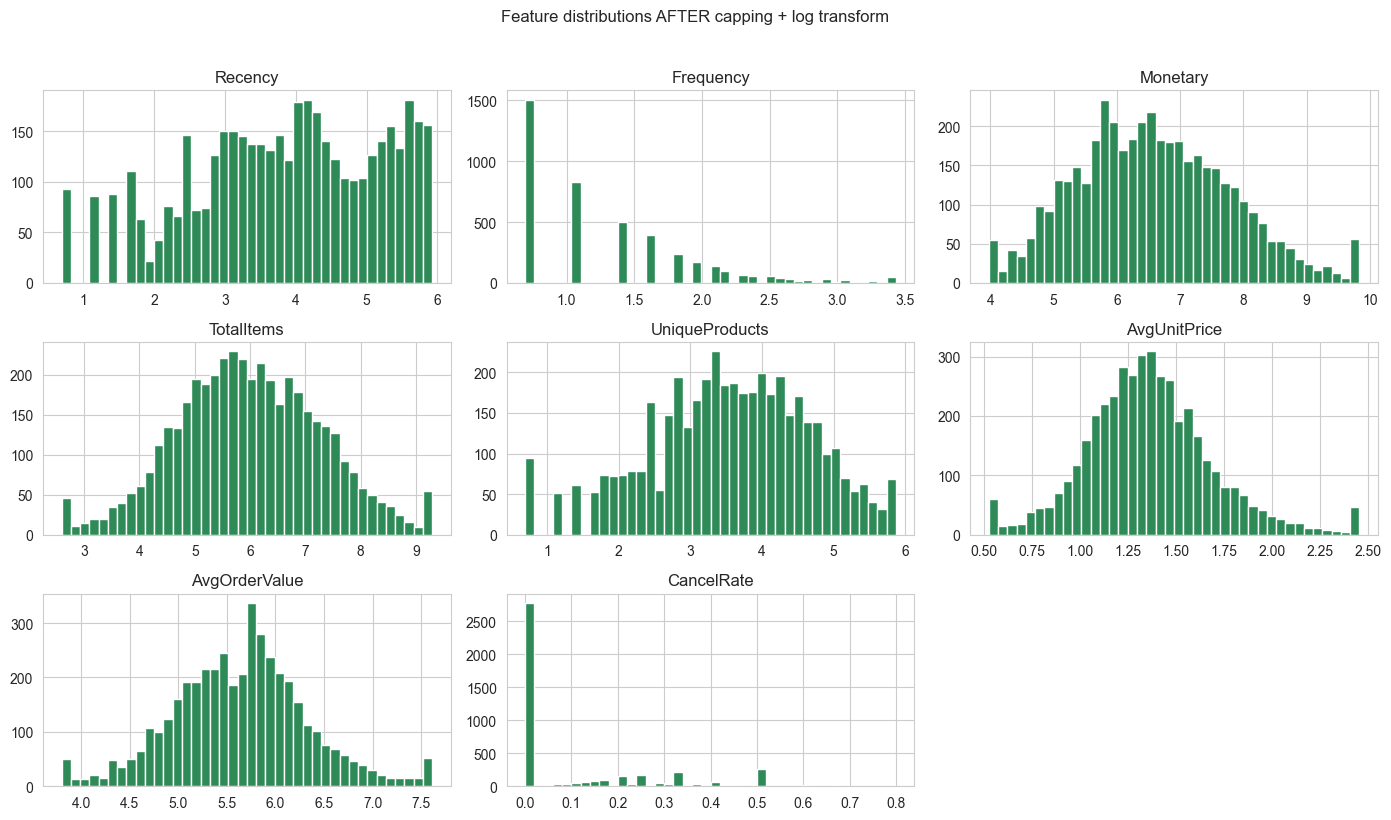

In [15]:
#Log transform to reduce skewness
# log1p = log(1 + x), safe for zeros. Recency, CancelRate are kept/handled below.
log_cols = ["Recency", "Frequency", "Monetary", "TotalItems", "UniqueProducts", "AvgUnitPrice", "AvgOrderValue"]
customer_log = customer_capped.copy()
customer_log[log_cols] = np.log1p(customer_log[log_cols])

print("Skewness after log transform:\n", customer_log.skew().sort_values(ascending=False))

customer_log.hist(bins=40, figsize=(14, 8), color="seagreen")
plt.suptitle("Feature distributions AFTER capping + log transform", y=1.02)
plt.tight_layout()
plt.show()

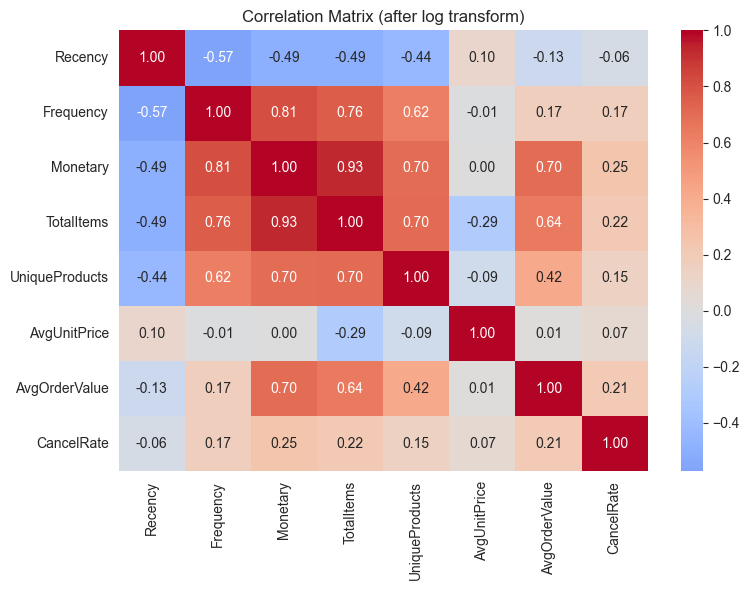

Most correlated pairs:
 Monetary    TotalItems        0.927829
Frequency   Monetary          0.812918
            TotalItems        0.756892
TotalItems  UniqueProducts    0.703157
Monetary    AvgOrderValue     0.698109
dtype: float64


In [16]:
#Check correlation (highly correlated features count the same information twice in distance calculations)
plt.figure(figsize=(8, 6))
sns.heatmap(customer_log.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Matrix (after log transform)")
plt.tight_layout()
plt.show()

corr = customer_log.corr().abs()
pairs = (corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
             .stack().sort_values(ascending=False))
print("Most correlated pairs:\n", pairs.head(5))

In [17]:
#Select the final features for clustering
# Drop features that are nearly duplicates of another one (|corr| > 0.9) so one idea is not over-weighted.
# TotalItems is largely redundant with Monetary / UniqueProducts, so we drop it if highly correlated.
high_corr_drop = [c for c in corr.columns if (corr[c].drop(c) > 0.9).any() and c == "TotalItems"]
print("Dropping highly correlated features:", high_corr_drop)

cluster_features = [c for c in customer_log.columns if c not in high_corr_drop]
X = customer_log[cluster_features]
print("Final features:", cluster_features)

Dropping highly correlated features: ['TotalItems']
Final features: ['Recency', 'Frequency', 'Monetary', 'UniqueProducts', 'AvgUnitPrice', 'AvgOrderValue', 'CancelRate']


In [18]:
#Feature Scaling (essential for clustering)
# K-Means, hierarchical and DBSCAN all use distances, so every feature must be on the same scale.
# Unlike the regression notebook there is no train/test split, so we fit the scaler on all customers.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_scaled_df = pd.DataFrame(X_scaled, columns=cluster_features, index=X.index)
print("Scaled data shape:", X_scaled_df.shape)
X_scaled_df.describe().T[["mean", "std", "min", "max"]].round(3)

Scaled data shape: (4334, 7)


,mean,std,min,max
Recency,0.0,1.0,-2.341,1.563
Frequency,0.0,1.0,-0.970,3.160
Monetary,0.0,1.0,-2.147,2.700
UniqueProducts,0.0,1.0,-2.540,2.070
AvgUnitPrice,0.0,1.0,-2.506,3.301
AvgOrderValue,-0.0,1.0,-2.630,2.828
CancelRate,-0.0,1.0,-0.637,4.185


In [19]:
print("=== FINAL PREPROCESSED DATA SUMMARY ===")
print("Customers (rows):", X_scaled_df.shape[0])
print("Features (columns):", X_scaled_df.shape[1])
print("Features:", cluster_features)
print("\nAny missing values left?", X_scaled_df.isnull().sum().sum())
print("Any infinite values?", np.isinf(X_scaled_df.values).sum())
print("\nPreprocessing complete. Ready for clustering.ipynb")

=== FINAL PREPROCESSED DATA SUMMARY ===
Customers (rows): 4334
Features (columns): 7
Features: ['Recency', 'Frequency', 'Monetary', 'UniqueProducts', 'AvgUnitPrice', 'AvgOrderValue', 'CancelRate']

Any missing values left? 0
Any infinite values? 0

Preprocessing complete. Ready for clustering.ipynb


In [20]:
#Before vs After Comparison Table
df_original = pd.read_csv("../data/online_retail.csv")

comparison = pd.DataFrame({
    "Stage": ["Original (transactions)", "Cleaned (transactions)", "Final (customers)"],
    "Rows": [df_original.shape[0], df.shape[0], X_scaled_df.shape[0]],
    "Columns": [df_original.shape[1], df.shape[1], X_scaled_df.shape[1]],
    "Missing Values": [df_original.isnull().sum().sum(), df.isnull().sum().sum(), X_scaled_df.isnull().sum().sum()],
    "Duplicate Rows": [df_original.duplicated().sum(), df.duplicated().sum(), X_scaled_df.duplicated().sum()]
})
comparison

,Stage,Rows,Columns,Missing Values,Duplicate Rows
0,Original (transactions),541910,8,136534,5268
1,Cleaned (transactions),391150,9,0,0
2,Final (customers),4334,7,0,0


In [21]:
# Save outputs (paths are relative to the notebooks/ folder, like the other notebooks)
import os
import joblib

os.makedirs("../data", exist_ok=True)
os.makedirs("../models", exist_ok=True)

# 1) Cleaned transaction-level dataset (same naming style as hotel_bookings_cleaned.csv)
df.to_csv("../data/online_retail_cleaned.csv", index=False)

# 2) Customer-level features (one row per customer)
customer_df.to_csv("../data/online_retail_customer_features.csv")          # readable, original units (for profiling clusters later)
X_scaled_df.to_csv("../data/online_retail_customer_features_scaled.csv")   # model-ready input for clustering

# 3) Fitted scaler goes in models/ (own name so it does not overwrite scaler.pkl)
joblib.dump(scaler, "../models/clustering_scaler.pkl")

print("Saved to ../data/:")
print("  online_retail_cleaned.csv                  ", df.shape)
print("  online_retail_customer_features.csv        ", customer_df.shape)
print("  online_retail_customer_features_scaled.csv ", X_scaled_df.shape)
print("Saved to ../models/: clustering_scaler.pkl")

Saved to ../data/:
  online_retail_cleaned.csv                   (391150, 9)
  online_retail_customer_features.csv         (4334, 8)
  online_retail_customer_features_scaled.csv  (4334, 7)
Saved to ../models/: clustering_scaler.pkl
